In [19]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import tensorflow 
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense

In [20]:
data = pd.read_csv("files/Churn_Modelling.csv")

In [21]:
data.shape

(10000, 14)

In [22]:
data.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [23]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.1 MB


In [24]:
data = data.drop(['RowNumber','CustomerId','Surname'],axis=1)

In [25]:
data

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...
9995,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9996,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9997,709,France,Female,36,7,0.00,1,0,1,42085.58,1
9998,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1


# One-hot Encoding

In [28]:
data.columns = data.columns.str.strip()

In [29]:
data = pd.get_dummies(data=data,columns=["Geography","Gender"], drop_first=True)
data

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,1,False,False,False
1,608,41,1,83807.86,1,0,1,112542.58,0,False,True,False
2,502,42,8,159660.80,3,1,0,113931.57,1,False,False,False
3,699,39,1,0.00,2,0,0,93826.63,0,False,False,False
4,850,43,2,125510.82,1,1,1,79084.10,0,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...
9995,771,39,5,0.00,2,1,0,96270.64,0,False,False,True
9996,516,35,10,57369.61,1,1,1,101699.77,0,False,False,True
9997,709,36,7,0.00,1,0,1,42085.58,1,False,False,False
9998,772,42,3,75075.31,2,1,0,92888.52,1,True,False,True


In [30]:
print(data.columns.tolist())

['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited', 'Geography_Germany', 'Geography_Spain', 'Gender_Male']


In [36]:
X = data.drop('Exited',axis=1)
y = data['Exited']

In [37]:
X_train,X_test , y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [38]:
X_train

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_Germany,Geography_Spain,Gender_Male
9254,686,32,6,0.00,2,1,1,179093.26,False,False,True
1561,632,42,4,119624.60,2,1,1,195978.86,True,False,True
1670,559,24,3,114739.92,1,1,0,85891.02,False,True,True
6087,561,27,9,135637.00,1,1,0,153080.40,False,False,False
6669,517,56,9,142147.32,1,0,0,39488.04,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...
5734,768,54,8,69712.74,1,1,1,69381.05,False,False,True
5191,682,58,1,0.00,1,1,1,706.50,False,False,False
5390,735,38,1,0.00,3,0,0,92220.12,False,False,False
860,667,43,8,190227.46,1,1,0,97508.04,False,False,True


In [39]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# create model

In [40]:
model = Sequential()

# Define input: 11 features
model.add(Input(shape=(11,)))

# Hidden layer: 11 neurons
model.add(Dense(11, activation='relu'))

# Hidden layer: 11 neurons
model.add(Dense(11, activation='relu'))


# Output layer:
model.add(Dense(1,activation='sigmoid'))

In [42]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 11)             │           132 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 11)             │           132 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            12 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 276 (1.08 KB)

 Trainable params: 276 (1.08 KB)

 Non-trainable params: 0 (0.00 B)

# compile

In [44]:
model.compile(loss='binary_crossentropy',optimizer='Adam',metrics=['accuracy'])

In [65]:
history = model.fit(X_train_scaled,y_train,epochs=100, validation_split=0.2)

Epoch 1/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8706 - loss: 0.3147 - val_accuracy: 0.8550 - val_loss: 0.3543
Epoch 2/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8712 - loss: 0.3147 - val_accuracy: 0.8544 - val_loss: 0.3547
Epoch 3/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8714 - loss: 0.3150 - val_accuracy: 0.8556 - val_loss: 0.3555
Epoch 4/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8711 - loss: 0.3148 - val_accuracy: 0.8550 - val_loss: 0.3556
Epoch 5/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8717 - loss: 0.3146 - val_accuracy: 0.8556 - val_loss: 0.3550
Epoch 6/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8731 - loss: 0.3146 - val_accuracy: 0.8550 - val_loss: 0.3553
Epoch 7/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8737 - loss: 0.3146 - val_accuracy: 0.8525 - val_loss: 0.3564
Epoch 8/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8697 - loss: 0.3150 - val_accu

# NOTE: Training and validation er accuracy increase should be must
- jodi training er accuracy bare but val_accuracy kome tahole overfitting hoise

In [66]:
model.layers[0].get_weights()

[array([[ 6.99924082e-02, -1.50676891e-01,  4.73454185e-02,
         -3.26353647e-02, -1.28240949e-02,  1.77148774e-01,
         -1.24349482e-01,  1.31804168e-01,  5.11491625e-03,
         -1.58062771e-01,  2.43539885e-01],
        [-9.33840513e-01,  1.34846628e+00, -8.69498849e-01,
         -4.81908061e-02, -6.21286929e-01,  5.29733956e-01,
          9.79825556e-01, -7.77347684e-02, -7.73768067e-01,
          6.61160886e-01,  2.38948941e-01],
        [-8.61676112e-02,  5.71070015e-02,  3.03906381e-01,
         -7.45524988e-02,  9.68541205e-02,  1.39956623e-01,
          2.45902538e-01,  2.23749559e-02, -1.42899603e-01,
         -1.39100716e-01, -1.36629805e-01],
        [ 2.52285344e-03,  1.03560008e-01, -1.56023204e-01,
          5.60396731e-01,  6.35038763e-02, -6.42242655e-02,
         -4.51281071e-01, -4.07949924e-01,  1.15399569e-01,
          8.17915320e-01, -1.33575812e-01],
        [ 3.77969623e-01,  7.41926581e-02,  9.91465524e-03,
          1.27694333e+00,  1.17685795e+00,  

In [67]:
y_log = model.predict(X_test_scaled)
y_pred = np.where(y_log > 0.5, 1,0)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  


In [68]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test,y_pred)

0.8595

# graph

In [69]:
import matplotlib.pyplot as plt
import seaborn as sns

In [70]:
history.history['loss']

[0.31468021869659424,
 0.3146626055240631,
 0.31496933102607727,
 0.3147956132888794,
 0.3145856559276581,
 0.314636766910553,
 0.31460171937942505,
 0.3149701654911041,
 0.3146288990974426,
 0.31499171257019043,
 0.3145902752876282,
 0.3147066831588745,
 0.3145327866077423,
 0.31489190459251404,
 0.31451666355133057,
 0.3141331374645233,
 0.31445997953414917,
 0.31432998180389404,
 0.31482264399528503,
 0.31419995427131653,
 0.31472769379615784,
 0.31427001953125,
 0.31431642174720764,
 0.31462740898132324,
 0.3144039511680603,
 0.31486839056015015,
 0.3141532838344574,
 0.314637154340744,
 0.3144223392009735,
 0.3143303692340851,
 0.31397387385368347,
 0.31427744030952454,
 0.3143050968647003,
 0.31439629197120667,
 0.31445449590682983,
 0.31460294127464294,
 0.3139365315437317,
 0.3143191635608673,
 0.31475698947906494,
 0.3147085905075073,
 0.3145624101161957,
 0.3145183324813843,
 0.3145187497138977,
 0.31421542167663574,
 0.3143366575241089,
 0.31416159868240356,
 0.3139223754405

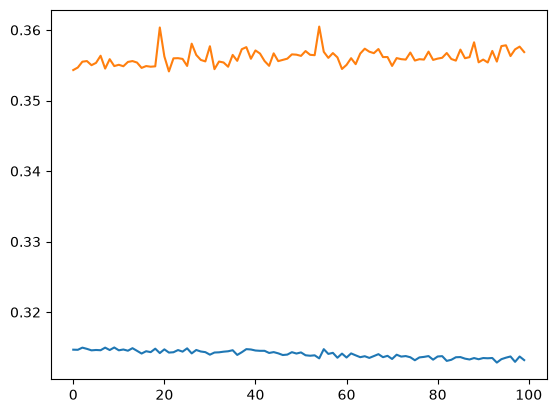

In [75]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

C:\Users\RoOnEy\AppData\Local\Temp\ipykernel_4220\3648399900.py:1: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.lineplot(data=history.history, x=history.history['loss'], y=history.history['val_loss'],palette=['blue', 'red'])


<Axes: >

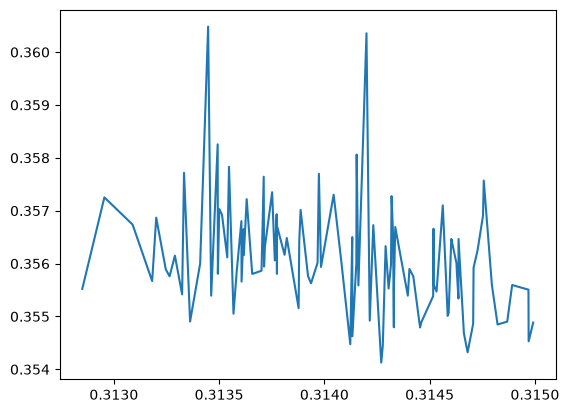

In [76]:
sns.lineplot(data=history.history, x=history.history['loss'], y=history.history['val_loss'],palette=['blue', 'red'])

In [77]:

df = pd.DataFrame({
    'Training Loss': history.history['loss'],
    'Validation Loss': history.history['val_loss']
})

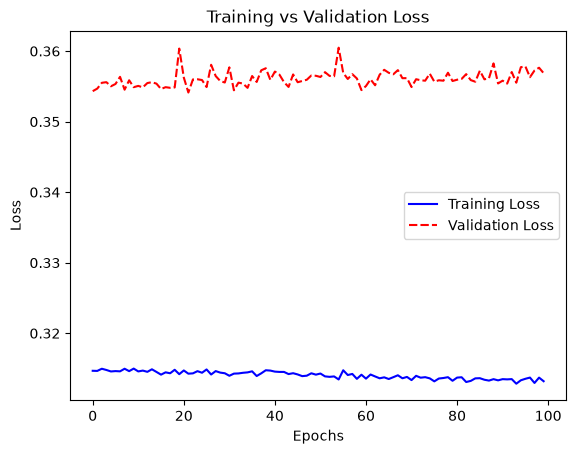

In [78]:
sns.lineplot(data=df, palette=['blue', 'red'])

plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training vs Validation Loss')
plt.show()